In [ ]:
%%bash
pip install -q ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.1 MB/s eta 0:00:00


# Proyecto Final - Minería de Datos
## Fase de Preparación de Datos (Metodología CRISP-DM)
**Dataset:** Credit Card Churn  
**Objetivo:** Realizar la limpieza y preparación inicial de los datos siguiendo los pasos vistos en clase (análisis exploratorio, pandas profiling, tratamiento de nulos con la regla del 15%, detección de atípicos y análisis de correlaciones), sin aplicar todavía balanceo ni transformaciones avanzadas, las cuales se trabajarán en el notebook de modelado.


### 1. Importación de librerías y carga de datos
Cargamos las librerías básicas para manipulación y visualización de datos, y leemos el archivo csv original.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Estilo visual básico
sns.set_style('whitegrid')

# Cargamos el archivo csv
df = pd.read_csv('credit_card_churn.csv')
print(f"Dimensiones iniciales: {df.shape[0]} filas y {df.shape[1]} columnas")
df.head()


Dimensiones iniciales: 10127 filas y 23 columnas


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


### 2. Pandas Profiling
Generamos el reporte con `ydata-profiling` para tener un resumen automatizado del dataset y lo guardamos en un archivo html para anexarlo a la entrega.


In [ ]:
from ydata_profiling import ProfileReport

# Excluimos las 2 columnas residuales del final para el reporte
cols_nb = [c for c in df.columns if 'Naive_Bayes' in c]
profile = ProfileReport(df.drop(columns=cols_nb), title="Reporte Profiling - Credit Card Churn", minimal=True)
profile.to_file("reporte_profiling_churn.html")
print("Reporte de Pandas Profiling guardado exitosamente como 'reporte_profiling_churn.html'")


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 21/21 [00:00<00:00, 56.02it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Reporte de Pandas Profiling guardado exitosamente como 'reporte_profiling_churn.html'


### 3. Selección inicial de variables (Eliminación de columnas no útiles)
Revisando el dataset y el diccionario encontramos 3 columnas que debemos quitar desde el inicio:
- Cliente : Es solo el ID del cliente, no tiene valor predictivo.
- Las dos columnas finales de `Naive_Bayes_Classifier

In [ ]:
# Eliminamos el ID y las columnas con fuga de datos
cols_eliminar = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]

df_limpio = df.drop(columns=cols_eliminar).copy()
print(f"Nuevo tamaño del dataset: {df_limpio.shape[0]} filas y {df_limpio.shape[1]} columnas")
print(f"Filas duplicadas: {df_limpio.duplicated().sum()}")


Nuevo tamaño del dataset: 10127 filas y 20 columnas
Filas duplicadas: 0


### 4. Revisión de la variable objetivo (`Attrition_Flag`)


Attrition_Flag
Existing Customer    83.934038
Attrited Customer    16.065962
Name: proportion, dtype: float64


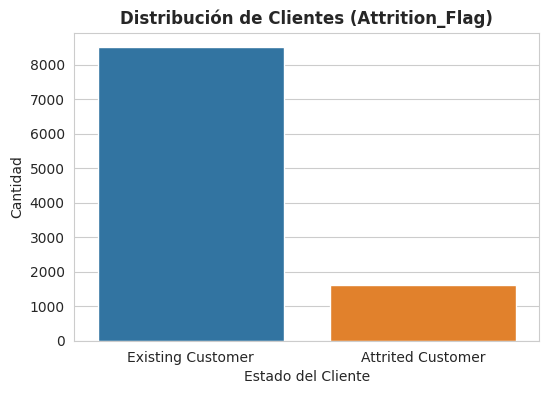

In [ ]:
# Conteo de la variable objetivo
print(df_limpio['Attrition_Flag'].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df_limpio, x='Attrition_Flag', palette=['#1f77b4', '#ff7f0e'])
plt.title("Distribución de Clientes (Attrition_Flag)", fontweight='bold')
plt.xlabel("Estado del Cliente")
plt.ylabel("Cantidad")
plt.show()


### 5. Reglas de calidad y atípicos (Tabla 4 del informe)
Al inspeccionar las variables categóricas, encontramos que `Education_Level`, `Marital_Status` e `Income_Category` tienen registros con el texto `'Unknown'`.
En el negocio esto no es una categoría real, sino un dato faltante que el banco no capturó. Por lo tanto, los convertimos a `NaN` para poder aplicarles la regla de limpieza de nulos.

En cuanto a las numéricas, revisamos mínimos y máximos para comprobar que no hayan edades negativas ni porcentajes mayores a 1.


In [ ]:
# Revisión de rangos de variables numéricas
print(df_limpio.describe().T[['min', 'mean', 'max']].round(2))

# Reemplazamos los 'Unknown' por NaN para tratarlos como valores nulos
df_nulos = df_limpio.replace('Unknown', np.nan)


                             min     mean       max
Customer_Age                26.0    46.33     73.00
Dependent_count              0.0     2.35      5.00
Months_on_book              13.0    35.93     56.00
Total_Relationship_Count     1.0     3.81      6.00
Months_Inactive_12_mon       0.0     2.34      6.00
Contacts_Count_12_mon        0.0     2.46      6.00
Credit_Limit              1438.3  8631.95  34516.00
Total_Revolving_Bal          0.0  1162.81   2517.00
Avg_Open_To_Buy              3.0  7469.14  34516.00
Total_Amt_Chng_Q4_Q1         0.0     0.76      3.40
Total_Trans_Amt            510.0  4404.09  18484.00
Total_Trans_Ct              10.0    64.86    139.00
Total_Ct_Chng_Q4_Q1          0.0     0.71      3.71
Avg_Utilization_Ratio        0.0     0.27      1.00


### 6. Limpieza de valores nulos (Regla del 15% - Tabla 5)
Aplicamos los tres pasos que pide la plantilla del informe:
1. **Eliminar filas con más del 15% de nulos:**  
   En nuestras 19 variables predictoras, si una fila tiene 3 valores faltantes tiene $3/19 = 15.79\% > 15\%$. Se encontraron 7 filas con esta condición y las eliminamos.
2. **Eliminar columnas con más del 15% de nulos:**  
   `Education_Level` tiene 15.00%, `Income_Category` tiene 10.98% y `Marital_Status` tiene 7.40%. Ninguna supera el 15%, por lo que no se borra ninguna columna.
3. **Imputar variables con menos del 15% de nulos:**  
   Como las tres variables son categóricas, se imputan con la **moda** de cada una:
   - `Education_Level` -> Moda: `'Graduate'`
   - `Income_Category` -> Moda: `'Less than $40K'`
   - `Marital_Status` -> Moda: `'Married'`


In [ ]:
# 1. Ver porcentaje de nulos por columna
porc_nulos = (df_nulos.isnull().sum() / len(df_nulos) * 100).round(2)
print("Porcentaje de nulos por columna:")
print(porc_nulos[porc_nulos > 0])

# 2. Eliminar registros con más del 15% de nulos (3 de 19 variables = 15.79%)
pred_cols = [c for c in df_nulos.columns if c != 'Attrition_Flag']
nulos_por_fila = (df_nulos[pred_cols].isnull().sum(axis=1) / len(pred_cols)) * 100
filas_a_borrar = (nulos_por_fila > 15.0).sum()
print(f"\nFilas eliminadas con > 15% de nulos: {filas_a_borrar}")

df_preparado = df_nulos.loc[nulos_por_fila <= 15.0].copy()

# 3. Imputar las columnas categóricas con su moda
for col in ['Education_Level', 'Income_Category', 'Marital_Status']:
    moda = df_preparado[col].mode()[0]
    df_preparado[col] = df_preparado[col].fillna(moda)
    print(f"- Imputada '{col}' con la moda: '{moda}'")

print(f"\nTotal de nulos restantes en el dataset: {df_preparado.isnull().sum().sum()}")
print(f"Dimensiones actuales: {df_preparado.shape[0]} filas y {df_preparado.shape[1]} columnas")


Porcentaje de nulos por columna:
Education_Level    15.00
Marital_Status      7.40
Income_Category    10.98
dtype: float64

Filas eliminadas con > 15% de nulos: 7
- Imputada 'Education_Level' con la moda: 'Graduate'
- Imputada 'Income_Category' con la moda: 'Less than $40K'
- Imputada 'Marital_Status' con la moda: 'Married'

Total de nulos restantes en el dataset: 0
Dimensiones actuales: 10120 filas y 20 columnas


### 7. Análisis de correlaciones (Redundancia e Irrelevancia)
Calculamos la matriz de correlación de Pearson entre las variables numéricas para ver si hay redundancia (multicolinealidad).
- Notamos que `Credit_Limit` y `Avg_Open_To_Buy` tienen una correlación de **0.996** (casi 1.0). Esto pasa porque contablemente el cupo disponible es el cupo total menos el saldo rotativo. Por tanto, eliminamos `Avg_Open_To_Buy` por redundancia.
- Otras relaciones como `Customer_Age` y `Months_on_book` (0.79) o `Total_Trans_Amt` y `Total_Trans_Ct` (0.81) son moderadas y las conservamos.


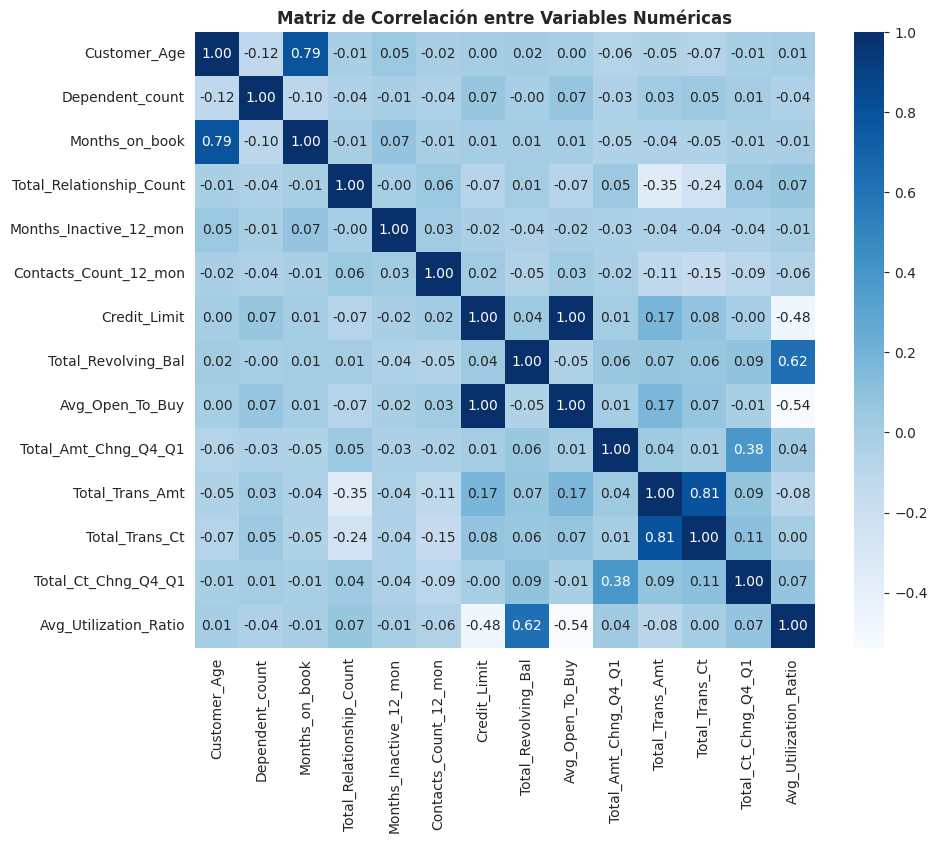

Dimensiones finales tras eliminar 'Avg_Open_To_Buy': 10120 filas x 19 columnas


In [ ]:
# Matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df_preparado.select_dtypes(include=[np.number]).corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Matriz de Correlación entre Variables Numéricas", fontweight='bold')
plt.show()

# Eliminamos la variable redundante Avg_Open_To_Buy (corr = 0.996 con Credit_Limit)
df_final = df_preparado.drop(columns=['Avg_Open_To_Buy']).copy()
print(f"Dimensiones finales tras eliminar 'Avg_Open_To_Buy': {df_final.shape[0]} filas x {df_final.shape[1]} columnas")


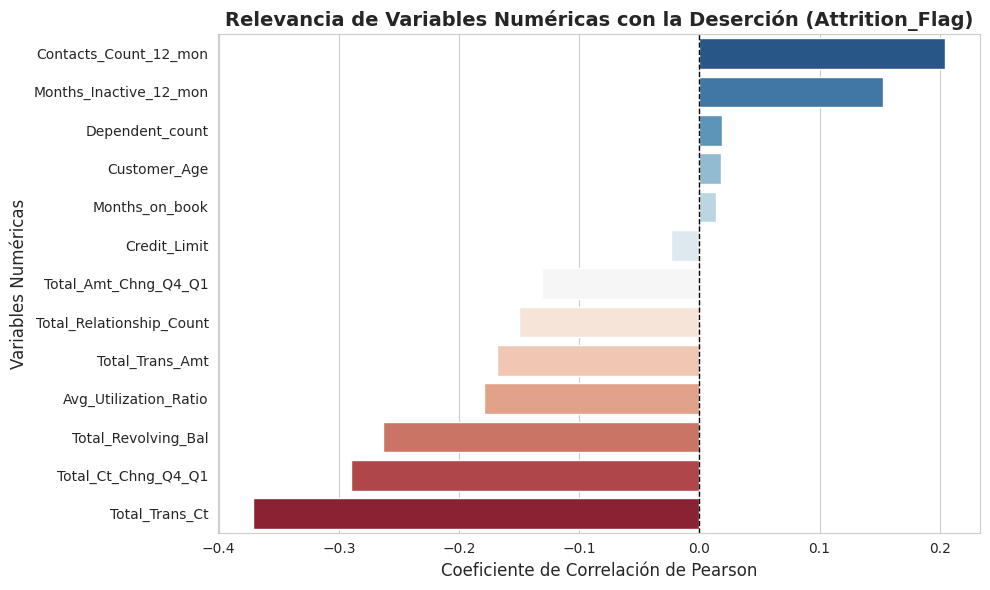

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Creamos una copia para el análisis de relevancia convirtiendo la variable objetivo a binaria
df_relevancia = df_final.copy()
df_relevancia['Attrition_Numeric'] = df_relevancia['Attrition_Flag'].apply(lambda x: 1 if x == 'Attrited Customer' else 0)

# Calculamos la correlación de las variables numéricas con la variable objetivo
correlaciones_relevancia = df_relevancia.select_dtypes(include=[np.number]).corr()['Attrition_Numeric'].drop('Attrition_Numeric')
correlaciones_relevancia = correlaciones_relevancia.sort_values(ascending=False)

# Graficamos la relevancia (correlación con Attrition_Flag)
plt.figure(figsize=(10, 6))
sns.barplot(x=correlaciones_relevancia.values, y=correlaciones_relevancia.index, palette='RdBu_r')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title("Relevancia de Variables Numéricas con la Deserción (Attrition_Flag)", fontsize=14, fontweight='bold')
plt.xlabel("Coeficiente de Correlación de Pearson", fontsize=12)
plt.ylabel("Variables Numéricas", fontsize=12)
plt.tight_layout()
plt.show()

### 8. Exportación del dataset limpio
Guardamos los datos listos en `credit_card_churn_limpio.csv` (10,120 filas y 19 columnas) para utilizarlos directamente en el Notebook 02 de Modelado Predictivo.


In [ ]:
# Guardamos el archivo depurado
df_final.to_csv("credit_card_churn_limpio.csv", index=False)
print("Archivo 'credit_card_churn_limpio.csv' guardado con éxito.")
print(f"Columnas resultantes ({len(df_final.columns)}): {list(df_final.columns)}")


Archivo 'credit_card_churn_limpio.csv' guardado con éxito.
Columnas resultantes (19): ['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
